In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, MaxPooling2D, Reshape, Multiply
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.applications import VGG16, VGG19, DenseNet121, ResNet50, MobileNet, InceptionV3, Xception
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns

2026-11-07 07:10:46.277553: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794035446.717877      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794035446.827431      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794035447.706991      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794035447.707037      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794035447.707039      23 computation_placer.cc:177] computation placer alr

In [2]:
# Parameters
input_shape = (224, 224, 3)
num_classes = 5
lr = 1e-5
bs = 32
ep = 30

# Define paths
base_dir = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
cropped_dirs = {
    cls: os.path.join(base_dir, cls, cls, "CROPPED")
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}
uncropped_dirs = {
    cls: os.path.join(base_dir, cls, cls)
    for cls in ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
}

In [3]:
import re

def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames

cropped_images, cropped_labels, cropped_groups = {}, {}, {}
for cls, dir_path in cropped_dirs.items():
    images, filenames = load_images_from_directory(dir_path)
    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)
    cropped_groups[cls] = np.array([f"{cls}_{re.split(r'[_.]', fn)[0]}" for fn in filenames])

X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups    = np.concatenate(list(cropped_groups.values()))

label_to_index = {cls: idx for idx, cls in enumerate(cropped_dirs.keys())}
y_cropped = np.array([label_to_index[label] for label in y_cropped])
y_cropped = to_categorical(y_cropped, num_classes=5)

def group_split_per_class(y_int, groups, fractions=(0.80, 0.15, 0.05)):
    rng = np.random.RandomState(42)
    split_of_group = {}
    for c in np.unique(y_int):
        idx = np.where(y_int == c)[0]
        ugroups = np.unique(groups[idx])
        rng.shuffle(ugroups)
        sizes = {g: np.sum(groups[idx] == g) for g in ugroups}
        targets = [f * len(idx) for f in fractions]
        filled = [0, 0, 0]
        for g in ugroups:
            s = int(np.argmax([(targets[k] - filled[k]) / targets[k] for k in range(3)]))
            split_of_group[g] = s
            filled[s] += sizes[g]
    return np.array([split_of_group[g] for g in groups])

split_id = group_split_per_class(y_cropped.argmax(axis=1), groups)

X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val,   y_val   = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test,  y_test  = X_cropped[split_id == 2], y_cropped[split_id == 2]

g_train, g_val, g_test = (set(groups[split_id == k]) for k in range(3))
assert not (g_train & g_val) and not (g_train & g_test) and not (g_val & g_test), "DATA LEAK!"
print(f"Train: {len(X_train)} imgs / {len(g_train)} groups")
print(f"Val  : {len(X_val)} imgs / {len(g_val)} groups")
print(f"Test : {len(X_test)} imgs / {len(g_test)} groups")

Train: 3192 imgs / 758 groups
Val  : 630 imgs / 148 groups
Test : 227 imgs / 60 groups


In [4]:
# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=20,         # Random rotation up to 20 degrees
    zoom_range=[0.8, 1.0],     # Zoom out by up to 20%
    brightness_range=[0.9, 1.1],  
    horizontal_flip=True,
    vertical_flip=True,
    preprocessing_function=lambda x: tf.image.adjust_contrast(x, np.random.uniform(0.9, 1.1)),  # Custom contrast adjustment
    fill_mode='nearest'
)

# Fit the generator to the training data
datagen.fit(X_train)

In [5]:
class ASCFBlock(tf.keras.layers.Layer):
    def __init__(self, num_clusters, **kwargs):
        super(ASCFBlock, self).__init__(**kwargs)
        self.num_clusters = num_clusters
        self.conv1x1 = tf.keras.layers.Conv2D(1, kernel_size=1, use_bias=False)
        self.dense = tf.keras.layers.Dense(num_clusters, activation='sigmoid')

    def call(self, feature_maps):
        batch_size = tf.shape(feature_maps)[0]
        h, w, num_channels = feature_maps.shape[1:]
        maps_per_cluster = num_channels // self.num_clusters
        
        reshaped = tf.reshape(feature_maps, (batch_size, h, w, self.num_clusters, maps_per_cluster))
        temp_batch = batch_size * self.num_clusters
        conv_input = tf.reshape(reshaped, (temp_batch, h, w, maps_per_cluster))
        
        fused = self.conv1x1(conv_input)
        fused = tf.reshape(fused, (batch_size, h, w, self.num_clusters))
        
        squeezed = tf.reduce_mean(fused, axis=[1, 2])
        weights = self.dense(squeezed)
        weighted = fused * tf.reshape(weights, (batch_size, 1, 1, self.num_clusters))
        
        final_map = tf.reduce_max(weighted, axis=-1, keepdims=True)
        vector_output = tf.reduce_mean(weighted, axis=[1, 2])
        
        return final_map, vector_output

    def compute_output_spec(self, input_spec):
        batch_size, h, w, num_channels = input_spec.shape
        if num_channels % self.num_clusters != 0:
            raise ValueError(f"Number of channels ({num_channels}) must be divisible by num_clusters ({self.num_clusters})")
        
        final_map_spec = tf.keras.KerasTensor(shape=(batch_size, h, w, 1), dtype=tf.float32)
        vector_output_spec = tf.keras.KerasTensor(shape=(batch_size, self.num_clusters), dtype=tf.float32)
        return final_map_spec, vector_output_spec



def se_block(x, ratio=16):
    channels = x.shape[-1]
    se = GlobalAveragePooling2D()(x)
    se = Dense(channels // ratio, activation='relu')(se)
    se = Dense(channels, activation='sigmoid')(se)
    se = Reshape((1, 1, channels))(se)
    return Multiply()([x, se])

In [6]:
input_layer = Input(shape=input_shape)

# Load pretrained VGG16 base model (without top layers)
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Pass the input_layer to the base model
x = base_model(input_layer)

x = Conv2D(1024, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((1, 1))(x)

x = Conv2D(2048, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = se_block(x)
x = MaxPooling2D((1, 1))(x)

# Global Average Pooling
# x = GlobalAveragePooling2D()(x)
ascf_layer = ASCFBlock(num_clusters=16)  # Set visualize=True to see feature maps during training
_, x = ascf_layer(x)

# Additional Dense Layers
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

# Output Layer
output_layer = Dense(num_classes, activation='softmax')(x)

# Define and compile the model
model = Model(inputs=input_layer, outputs=output_layer)
model.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

I0000 00:00:1794035992.489184      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794035992.495216      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 7, 7,      │  4,719,616 │ vgg16[0][0]       │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 7, 7,      │      4,096 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 7, 7,      │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7,      │ 18,876,416 │ max_pooling2d[0]… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7,      │      8,192 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 2048)      │    264,192 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1,      │          0 │ dense_1[0][0]     │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 7, 7,      │          0 │ batch_normalizat… │
│                     │ 2048)             │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 7, 7,      │          0 │ multiply[0][0]    │
│ (MaxPooling2D)      │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ascf_block          │ [(None, 7, 7, 1), │        400 │ max_pooling2d_1[… │
│ (ASCFBlock)         │ (None, 16)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1024)      │     17,408 │ ascf_block[0][1]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1024)      │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 512)       │    524,800 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 512)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 5)         │      2,565 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 39,394,645 (150.28 MB)

 Trainable params: 39,388,501 (150.26 MB)

 Non-trainable params: 6,144 (24.00 KB)

In [7]:
class_counts = np.sum(y_train, axis=0)           
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(num_classes),
    y=np.argmax(y_train, axis=1)
)

class_weight_dict = dict(enumerate(class_weights))

print("Class counts (train):", class_counts.astype(int))
print("Class weights:", class_weight_dict)

Class counts (train): [637 627 643 624 661]
Class weights: {0: np.float64(1.0021978021978022), 1: np.float64(1.018181818181818), 2: np.float64(0.9928460342146189), 3: np.float64(1.023076923076923), 4: np.float64(0.9658093797276853)}


In [8]:
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1794036003.940955      67 service.cc:152] XLA service 0x7a7acc00a490 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794036003.941003      67 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1794036003.941010      67 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1794036005.526359      67 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-11-07 07:20:31.968020: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:20:32.162913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:20:33.906190: E external/local_xl

 11/100 ━━━━━━━━━━━━━━━━━━━━ 1:15 852ms/step - accuracy: 0.2185 - loss: 1.5980

2026-11-07 07:21:28.095523: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:21:28.292962: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:21:29.748553: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:21:29.922345: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-07 07:21:33.438017: E external/local_xla/xla/stream_

100/100 ━━━━━━━━━━━━━━━━━━━━ 232s 2s/step - accuracy: 0.4317 - loss: 1.4468 - val_accuracy: 0.7587 - val_loss: 0.7587
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 982ms/step - accuracy: 0.8186 - loss: 0.5840 - val_accuracy: 0.9079 - val_loss: 0.2724
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 981ms/step - accuracy: 0.9150 - loss: 0.3274 - val_accuracy: 0.8476 - val_loss: 0.4953
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 979ms/step - accuracy: 0.9235 - loss: 0.2507 - val_accuracy: 0.9079 - val_loss: 0.2233
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 982ms/step - accuracy: 0.9457 - loss: 0.2155 - val_accuracy: 0.9349 - val_loss: 0.2003
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 983ms/step - accuracy: 0.9539 - loss: 0.1598 - val_accuracy: 0.9032 - val_loss: 0.2609
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 984ms/step - accuracy: 0.9636 - loss: 0.1428 - val_accuracy: 0.9365 - val_loss: 0.2066
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 98s 984ms/step - accuracy: 0.9550 - loss: 0.1482 - val_a

8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 826ms/step - accuracy: 0.9602 - loss: 0.1111
Test Loss: 0.113123
Test Accuracy: 0.960352


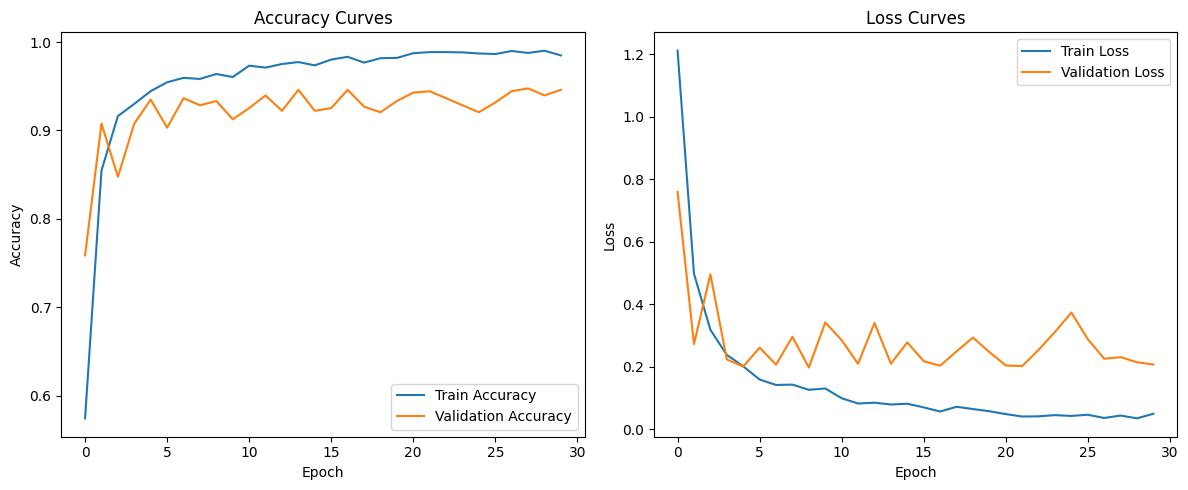

8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 334ms/step
Classification Report (Test Set):
                             precision    recall  f1-score   support

            im_Dyskeratotic   1.000000  0.977778  0.988764        45
             im_Metaplastic   0.904762  0.926829  0.915663        41
            im_Koilocytotic   0.981818  0.915254  0.947368        59
               im_Parabasal   0.906977  1.000000  0.951220        39
im_Superficial-Intermediate   1.000000  1.000000  1.000000        43

                   accuracy                       0.960352       227
                  macro avg   0.958711  0.963972  0.960603       227
               weighted avg   0.962091  0.960352  0.960480       227



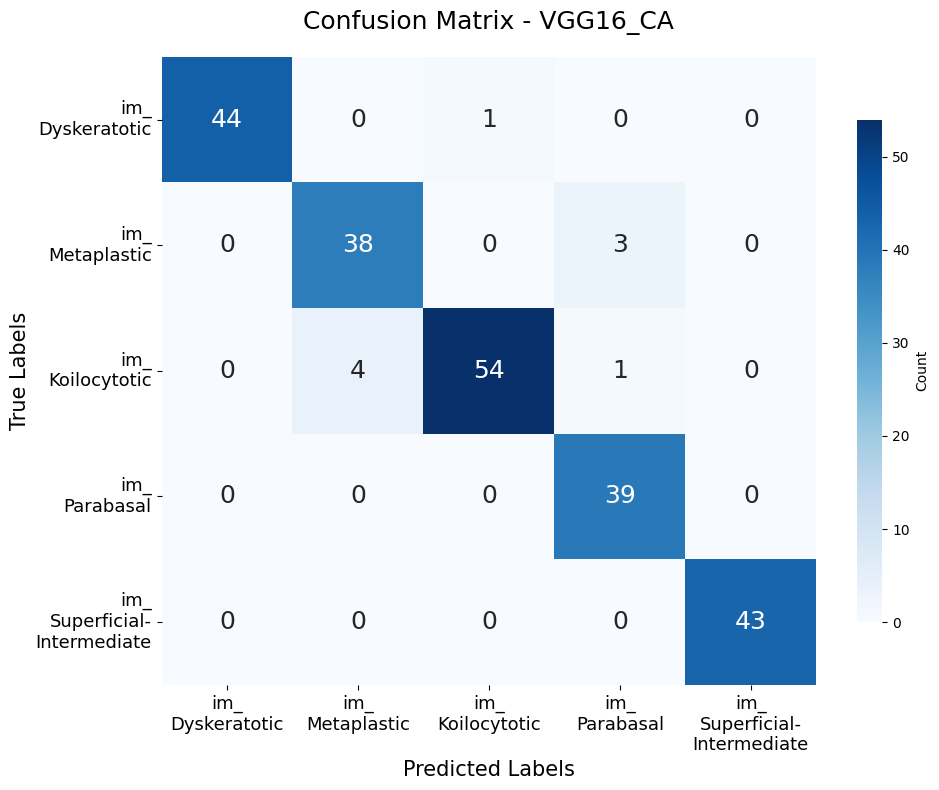

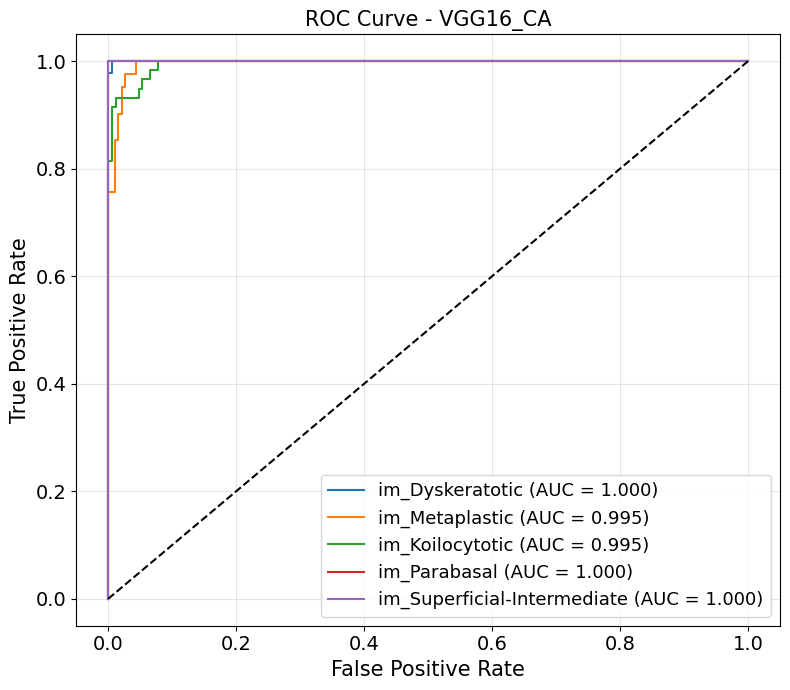

Model saved successfully.


In [9]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.6f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report (Test Set):")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
class_names = list(label_to_index.keys())
class_names_wrapped = [
    name.replace('_', '_\n').replace('-', '-\n')
    for name in class_names
]
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))           

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 18},           
    cbar_kws={"label": "Count", "shrink": 0.8}
)

# Font size adjustments
plt.xticks(fontsize=13, rotation=0, ha='center')   
plt.yticks(fontsize=13, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels",      fontsize=15)
plt.title("Confusion Matrix - VGG16_CA", fontsize=18, pad=20)

plt.tight_layout()
plt.show()


# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - VGG16_CA',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()


# ===============================
# Save Model
# ===============================
model.save("cervical_cancer_model.h5")
print("Model saved successfully.")

In [10]:
input_layer = Input(shape=input_shape)

# Load pretrained VGG16 base model (without top layers)
base_model_gap = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Pass the input_layer to the base model
x = base_model_gap(input_layer)

x = Conv2D(1024, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling2D((1, 1))(x)

x = Conv2D(2048, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = se_block(x)
x = MaxPooling2D((1, 1))(x)

# Global Average Pooling
x = GlobalAveragePooling2D()(x)
# ascf_layer = ASCFBlock(num_clusters=16)  # Set visualize=True to see feature maps during training
# _, x = ascf_layer(x)

# Additional Dense Layers
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)

# Output Layer
output_layer = Dense(num_classes, activation='softmax')(x)

# Define and compile the model
model_gap = Model(inputs=input_layer, outputs=output_layer)
model_gap.compile(optimizer=Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
model_gap.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 7, 7,      │  4,719,616 │ vgg16[0][0]       │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7,      │      4,096 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 7, 7,      │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 7, 7,      │ 18,876,416 │ max_pooling2d_2[… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7,      │      8,192 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 2048)      │    264,192 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1,      │          0 │ dense_7[0][0]     │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 7, 7,      │          0 │ batch_normalizat… │
│ (Multiply)          │ 2048)             │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 7, 7,      │          0 │ multiply_1[0][0]  │
│ (MaxPooling2D)      │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ max_pooling2d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1024)      │  2,098,176 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1024)      │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 512)       │    524,800 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 512)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 5)         │      2,565 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 41,475,013 (158.21 MB)

 Trainable params: 41,468,869 (158.19 MB)

 Non-trainable params: 6,144 (24.00 KB)

In [11]:
history = model_gap.fit(
    datagen.flow(X_train, y_train, batch_size=bs),
    validation_data=(X_val, y_val),
    epochs=ep,
    batch_size=bs,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.5441 - loss: 1.1589 - val_accuracy: 0.8333 - val_loss: 0.5335
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.8997 - loss: 0.3171 - val_accuracy: 0.9286 - val_loss: 0.2269
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9362 - loss: 0.2079 - val_accuracy: 0.9111 - val_loss: 0.1926
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9403 - loss: 0.1734 - val_accuracy: 0.9492 - val_loss: 0.1642
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9451 - loss: 0.1517 - val_accuracy: 0.9317 - val_loss: 0.2463
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9619 - loss: 0.1254 - val_accuracy: 0.9286 - val_loss: 0.2324
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9663 - loss: 0.1053 - val_accuracy: 0.9397 - val_loss: 0.1715
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.9626 - loss: 0.1134 - val_accu

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 289ms/step - accuracy: 0.9129 - loss: 0.2761
Test Loss: 0.191869
Test Accuracy: 0.938326


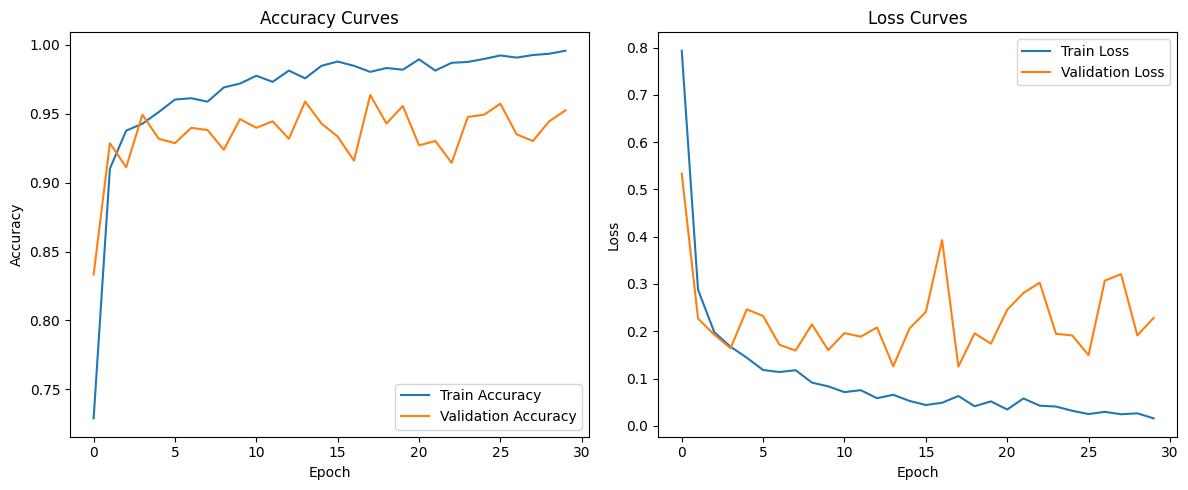

8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 348ms/step
Classification Report:
                             precision    recall  f1-score   support

            im_Dyskeratotic   1.000000  0.844444  0.915663        45
             im_Metaplastic   0.906977  0.951220  0.928571        41
            im_Koilocytotic   0.870968  0.915254  0.892562        59
               im_Parabasal   0.975000  1.000000  0.987342        39
im_Superficial-Intermediate   0.977273  1.000000  0.988506        43

                   accuracy                       0.938326       227
                  macro avg   0.946043  0.942184  0.942529       227
               weighted avg   0.941061  0.938326  0.938103       227



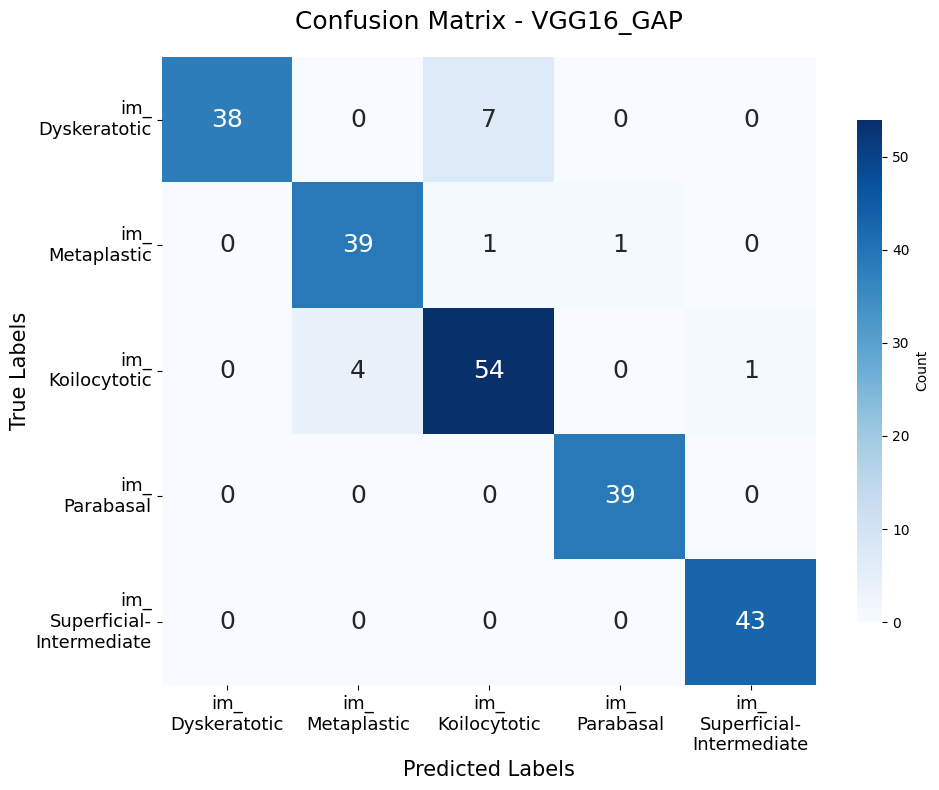

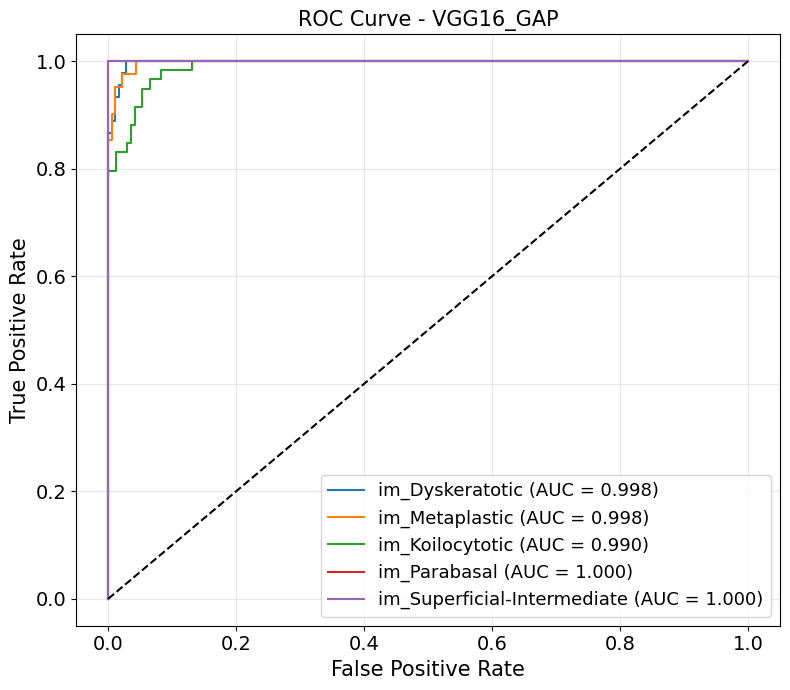

Model saved successfully.


In [12]:
# ===============================
# Final Test Evaluation
# ===============================
test_loss, test_accuracy = model_gap.evaluate(X_test, y_test, verbose=1)
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.6f}")


# ===============================
# Training Curves (Train + Val)
# ===============================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ===============================
# Predictions on TEST set only
# ===============================
y_pred_test = model_gap.predict(X_test, verbose=1)

y_pred_classes = np.argmax(y_pred_test, axis=1)
y_true_classes = np.argmax(y_test, axis=1)


# ===============================
# Classification Report (TEST)
# ===============================
print("Classification Report:")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=list(cropped_dirs.keys()),
        digits=6
    )
)


# ===============================
# Confusion Matrix (TEST)
# ===============================
class_names = list(label_to_index.keys())
class_names_wrapped = [
    name.replace('_', '_\n').replace('-', '-\n')
    for name in class_names
]
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))           # increased size → more space for long names

# Heatmap with bigger annotation font
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names_wrapped,
    yticklabels=class_names_wrapped,
    annot_kws={"size": 18},           # bigger numbers inside cells
    cbar_kws={"label": "Count", "shrink": 0.8}
)

# Font size adjustments
plt.xticks(fontsize=13, rotation=0, ha='center')   # horizontal + centered
plt.yticks(fontsize=13, rotation=0)

plt.xlabel("Predicted Labels", fontsize=15)
plt.ylabel("True Labels",      fontsize=15)
plt.title("Confusion Matrix - VGG16_GAP", fontsize=18, pad=20)

plt.tight_layout()
plt.show()


# ===============================
# ROC Curve & AUC (TEST)
# ===============================
num_classes = y_test.shape[1]
fpr = {}
tpr = {}
roc_auc = {}

class_names = list(label_to_index.keys())          

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 7))   

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.3f})'   
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate',      fontsize=15)
plt.ylabel('True Positive Rate',      fontsize=15)
plt.title('ROC Curve - VGG16_GAP',      fontsize=15)
plt.legend(loc='lower right', fontsize=13)
plt.grid(True, alpha=0.3)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

# ===============================
# Save Model
# ===============================
model_gap.save("cervical_cancer_model_gap.h5")
print("Model saved successfully.")